In [5]:

from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

import pandas as pd

DATA_DIR = Path("../data/raw/NEU-DET")

def inspect_split(split):
    image_dir = DATA_DIR / split / "images"
    annotation_dir = DATA_DIR / split / "annotations"

    images = {
        p.name: p
        for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    }

    xml_files = list(annotation_dir.rglob("*.xml"))

    rows = []
    missing_images = []
    invalid_boxes = []
    class_counts = Counter()

    for xml_path in xml_files:
        root = ET.parse(xml_path).getroot()
        filename = root.findtext("filename")

        if not filename or filename not in images:
            missing_images.append((xml_path.name, filename))
            continue

        size = root.find("size")
        width = int(size.findtext("width"))
        height = int(size.findtext("height"))

        for obj in root.findall("object"):
            label = obj.findtext("name")
            box = obj.find("bndbox")

            xmin = int(box.findtext("xmin"))
            ymin = int(box.findtext("ymin"))
            xmax = int(box.findtext("xmax"))
            ymax = int(box.findtext("ymax"))

            valid = (
                0 <= xmin < xmax <= width
                and 0 <= ymin < ymax <= height
            )

            if not valid:
                invalid_boxes.append(xml_path.name)

            class_counts[label] += 1

            rows.append({
                "split": split,
                "image": filename,
                "class": label,
                "width": width,
                "height": height,
                "xmin": xmin,
                "ymin": ymin,
                "xmax": xmax,
                "ymax": ymax,
                "box_area_ratio": (
                    (xmax - xmin) * (ymax - ymin)
                    / (width * height)
                ),
                "valid_box": valid,
            })

    df = pd.DataFrame(rows)

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("XML files:", len(xml_files))
    print("Matched annotations:", len(xml_files) - len(missing_images))
    print("Missing image matches:", len(missing_images))
    print("Invalid boxes:", len(invalid_boxes))
    print("Classes:", dict(class_counts))

    if not df.empty:
        print("\nBounding-box area ratio:")
        print(df["box_area_ratio"].describe())

        print("\nClass-wise box area ratio:")
        print(
            df.groupby("class")["box_area_ratio"]
            .agg(["count", "mean", "min", "max"])
            .round(3)
        )

    return df, missing_images, invalid_boxes


train_df, train_missing, train_invalid = inspect_split("train")
val_df, val_missing, val_invalid = inspect_split("validation")



--- TRAIN ---
Images: 1440
XML files: 1439
Matched annotations: 1265
Missing image matches: 174
Invalid boxes: 0
Classes: {'crazing': 524, 'patches': 586, 'inclusion': 852, 'pitted_surface': 169, 'rolled-in_scale': 496, 'scratches': 427}

Bounding-box area ratio:
count    3054.000000
mean        0.146427
std         0.149954
min         0.002700
25%         0.047000
50%         0.102700
75%         0.193788
max         0.980075
Name: box_area_ratio, dtype: float64

Class-wise box area ratio:
                 count   mean    min    max
class                                      
crazing            524  0.226  0.056  0.917
inclusion          852  0.071  0.006  0.497
patches            586  0.126  0.010  0.660
pitted_surface     169  0.531  0.021  0.980
rolled-in_scale    496  0.134  0.014  0.589
scratches          427  0.090  0.003  0.458

--- VALIDATION ---
Images: 360
XML files: 361
Matched annotations: 360
Missing image matches: 1
Invalid boxes: 0
Classes: {'crazing': 162, 'inclusion

In [8]:

from pathlib import Path
import xml.etree.ElementTree as ET
from collections import Counter

DATA_DIR = Path("../data/raw/NEU-DET")

for split in ["train", "validation"]:
    image_dir = DATA_DIR / split / "images"
    annotation_dir = DATA_DIR / split / "annotations"

    image_paths = [
        p for p in image_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    ]

    # Keep all paths instead of overwriting duplicate basenames.
    images_by_name = {}
    for path in image_paths:
        images_by_name.setdefault(path.name.lower(), []).append(path)

    xml_paths = list(annotation_dir.rglob("*.xml"))
    missing = []

    for xml_path in xml_paths:
        root = ET.parse(xml_path).getroot()
        filename = root.findtext("filename")

        if not filename or filename.lower() not in images_by_name:
            missing.append((xml_path, filename))

    print(f"\n--- {split.upper()} ---")
    print("Unmatched XML files:", len(missing))

    for xml_path, filename in missing[:20]:
        print(
            "XML:", xml_path.name,
            "| Referenced image:", repr(filename)
        )

    print("\nSample image paths:")
    for path in image_paths[:5]:
        print(path)



--- TRAIN ---
Unmatched XML files: 174
XML: patches_104.xml | Referenced image: 'patches_104'
XML: patches_106.xml | Referenced image: 'patches_106'
XML: patches_107.xml | Referenced image: 'patches_107'
XML: patches_12.xml | Referenced image: 'patches_12'
XML: patches_157.xml | Referenced image: 'patches_157'
XML: patches_158.xml | Referenced image: 'patches_158'
XML: patches_159.xml | Referenced image: 'patches_159'
XML: patches_160.xml | Referenced image: 'patches_160'
XML: patches_161.xml | Referenced image: 'patches_161'
XML: patches_162.xml | Referenced image: 'patches_162'
XML: patches_163.xml | Referenced image: 'patches_163'
XML: patches_164.xml | Referenced image: 'patches_164'
XML: patches_166.xml | Referenced image: 'patches_166'
XML: patches_169.xml | Referenced image: 'patches_169'
XML: patches_17.xml | Referenced image: 'patches_17'
XML: patches_170.xml | Referenced image: 'patches_170'
XML: patches_173.xml | Referenced image: 'patches_173'
XML: patches_177.xml | Refere

In [9]:

from pathlib import Path
import xml.etree.ElementTree as ET

DATA_DIR = Path("../data/raw/NEU-DET")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def build_image_index(image_dir):
    index = {}

    for path in image_dir.rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            index[path.name.lower()] = path
            index[path.stem.lower()] = path

    return index

for split in ["train", "validation"]:
    image_dir = DATA_DIR / split / "images"
    annotation_dir = DATA_DIR / split / "annotations"

    image_index = build_image_index(image_dir)
    xml_files = list(annotation_dir.rglob("*.xml"))

    resolved = []
    unresolved = []

    for xml_path in xml_files:
        root = ET.parse(xml_path).getroot()
        filename = root.findtext("filename")

        if not filename:
            unresolved.append((xml_path.name, filename))
            continue

        key = Path(filename).name.lower()
        stem = Path(filename).stem.lower()

        image_path = image_index.get(key) or image_index.get(stem)

        if image_path is None:
            unresolved.append((xml_path.name, filename))
        else:
            resolved.append((xml_path.name, image_path))

    print(f"\n--- {split.upper()} ---")
    print("XML files:", len(xml_files))
    print("Successfully resolved:", len(resolved))
    print("Unresolved:", len(unresolved))

    for xml_name, filename in unresolved[:20]:
        print("Unresolved:", xml_name, "->", repr(filename))



--- TRAIN ---
XML files: 1439
Successfully resolved: 1439
Unresolved: 0

--- VALIDATION ---
XML files: 361
Successfully resolved: 360
Unresolved: 1
Unresolved: crazing_240.xml -> 'crazing_240.jpg'


In [10]:

split = "validation"

image_dir = DATA_DIR / split / "images"
annotation_dir = DATA_DIR / split / "annotations"

print("Images matching crazing_240:")
for path in image_dir.rglob("*"):
    if "crazing_240" in path.name.lower():
        print(path)

xml_path = annotation_dir / "crazing_240.xml"

if xml_path.exists():
    root = ET.parse(xml_path).getroot()
    print("\nXML filename:", repr(root.findtext("filename")))


Images matching crazing_240:

XML filename: 'crazing_240.jpg'


In [11]:

from pathlib import Path

DATA_DIR = Path("../data/raw/NEU-DET")

target = "crazing_240"

print("Searching the entire dataset...")

matches = [
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
    and p.stem.lower() == target.lower()
]

if matches:
    for path in matches:
        print("Found:", path)
else:
    print("No image with this filename exists in the dataset.")


Searching the entire dataset...
Found: ..\data\raw\NEU-DET\train\images\crazing\crazing_240.jpg
Found: ..\data\raw\NEU-DET\validation\annotations\crazing_240.xml


Annotation filename: crazing_240.jpg
Annotation class: crazing
Bounding box: {'xmin': 12, 'ymin': 2, 'xmax': 176, 'ymax': 58}


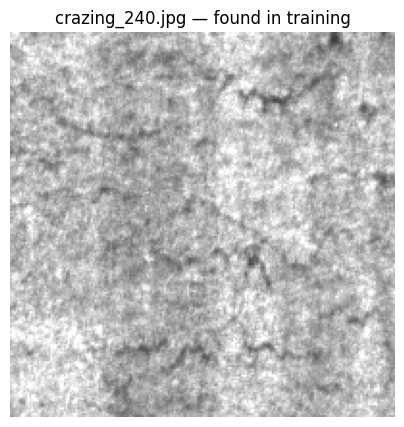

In [12]:

from pathlib import Path
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw/NEU-DET")

image_path = (
    DATA_DIR / "train" / "images"
    / "crazing" / "crazing_240.jpg"
)

xml_path = (
    DATA_DIR / "validation" / "annotations"
    / "crazing_240.xml"
)

root = ET.parse(xml_path).getroot()

print("Annotation filename:", root.findtext("filename"))
print("Annotation class:", root.findtext("object/name"))

box = root.find("object/bndbox")
print("Bounding box:", {
    key: int(box.findtext(key))
    for key in ["xmin", "ymin", "xmax", "ymax"]
})

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("crazing_240.jpg — found in training")
plt.axis("off")
plt.show()


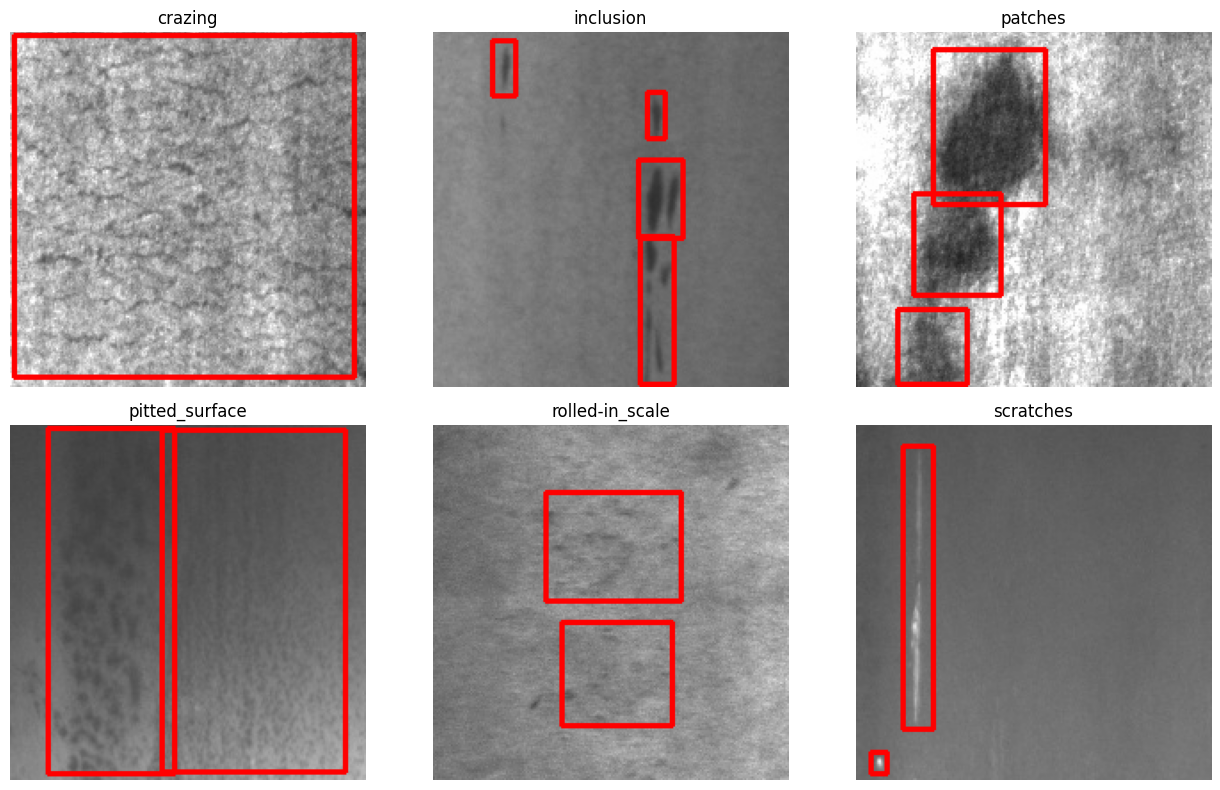

In [13]:

from pathlib import Path
import xml.etree.ElementTree as ET

import cv2
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/raw/NEU-DET")

CLASSES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches",
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for ax, class_name in zip(axes.flat, CLASSES):
    annotation_dir = DATA_DIR / "train" / "annotations"
    image_dir = DATA_DIR / "train" / "images" / class_name

    xml_files = sorted(annotation_dir.glob(f"{class_name}_*.xml"))

    selected = None

    for xml_path in xml_files:
        root = ET.parse(xml_path).getroot()
        filename = root.findtext("filename")

        # Match image stems so extensionless XML filenames also work.
        if not filename:
            continue

        candidates = list(image_dir.glob(Path(filename).stem + ".*"))

        if candidates:
            selected = (root, candidates[0])
            break

    if selected is None:
        ax.set_title(f"{class_name}: no matched image")
        ax.axis("off")
        continue

    root, image_path = selected
    image = cv2.imread(str(image_path))

    if image is None:
        ax.set_title(f"{class_name}: unreadable")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for obj in root.findall("object"):
        box = obj.find("bndbox")
        xmin = int(box.findtext("xmin"))
        ymin = int(box.findtext("ymin"))
        xmax = int(box.findtext("xmax"))
        ymax = int(box.findtext("ymax"))

        cv2.rectangle(
            image,
            (xmin, ymin),
            (xmax, ymax),
            (255, 0, 0),
            2,
        )

    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()
